# P49: Roman GBTDS noise and systematics survey — figures
Regenerates every README figure. All inputs are literature numbers hard-coded (with citations) in `figlib.py` plus the WG6 sigma table in `tools/make_roman_rotators.py`; no drive, no downloads.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
HERE = Path.cwd()
if not (HERE / 'figlib.py').exists():
    HERE = next(p for p in [HERE, *HERE.parents] if (p / 'reports/2026-11-19_roman-noise-survey/figlib.py').exists()) / 'reports/2026-11-19_roman-noise-survey'
sys.path.insert(0, str(HERE))
import os; os.chdir(HERE)
import figlib

## 1. Per-exposure sigma vs F146
WG6 improved sigma vs a CCD-equation evaluation of the Wilson+2023 Table 1 parameters (66 s, 3x3 aperture, assumed 83% aperture fraction), with the Penny+2019 1 mmag floor or the Wilson+2023 1.3 ppt floor. Purple markers are precision points quoted in text.

 f146  wg6_improved_mmag  wg6_simple_mmag  ccd_nofloor_mmag  ccd_penny_floor_mmag  ccd_wilson_floor_mmag
 14.0               1.00            1.000             0.273                 1.037                  1.438
 16.0               1.15            1.396             0.688                 1.214                  1.570
 17.0               1.27            1.650             1.091                 1.480                  1.784
 18.0               1.62            2.200             1.737                 2.004                  2.238
 19.0               2.72            3.603             2.781                 2.955                  3.118
 20.0               4.27            5.900             4.516                 4.626                  4.732
 21.0              10.25           10.305             7.575                 7.640                  7.705
 22.0              13.14           18.000            13.524                13.561                 13.597


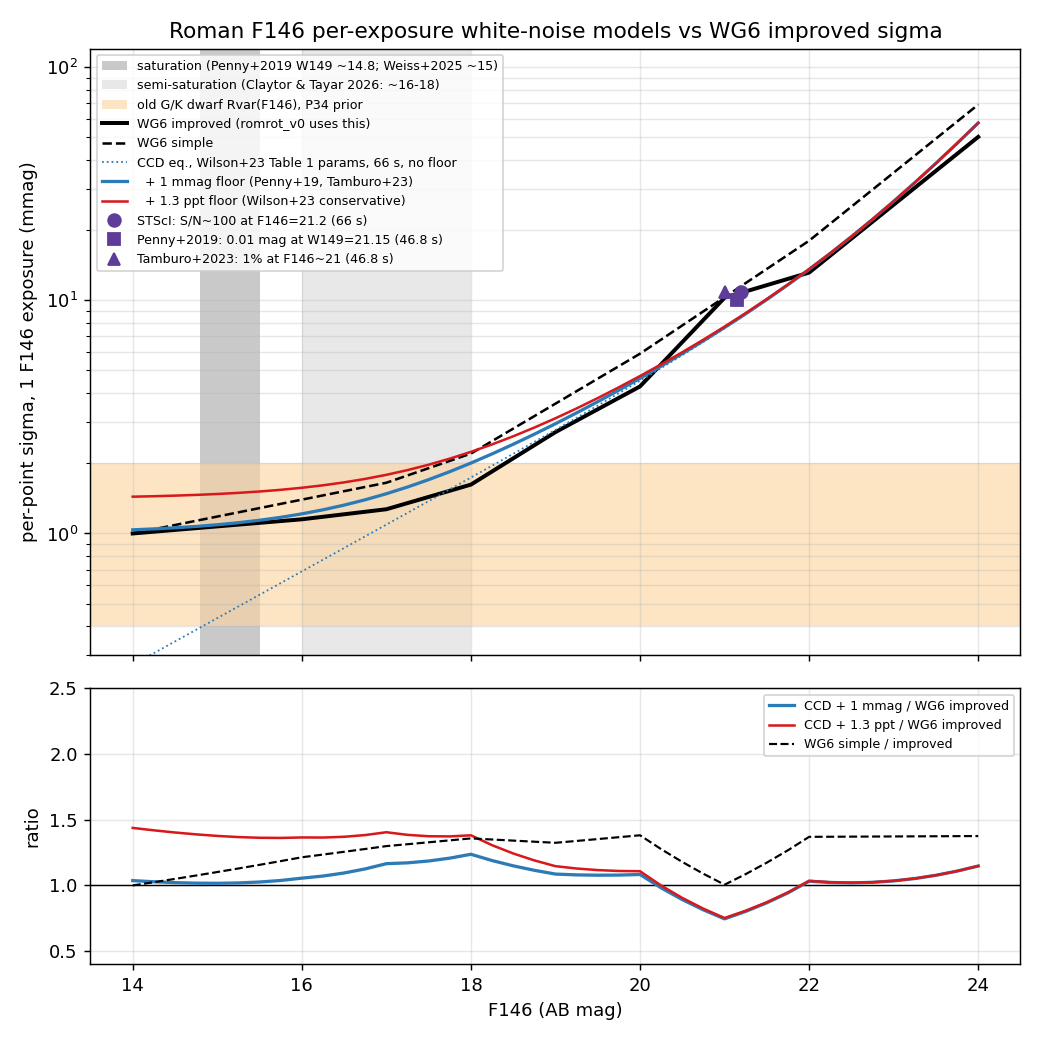

In [2]:
df = figlib.fig_sigma()
print(df[df.f146.isin([14,16,17,18,19,20,21,22])].round(3).to_string(index=False))
display(Image('figures/sigma_vs_f146.png'))

## 2. Timescales of GBTDS noise/systematics vs rotation periods
Red = time-correlated, orange = steps/offsets, blue = gaps. Bracket text: which model/simulator includes the effect.

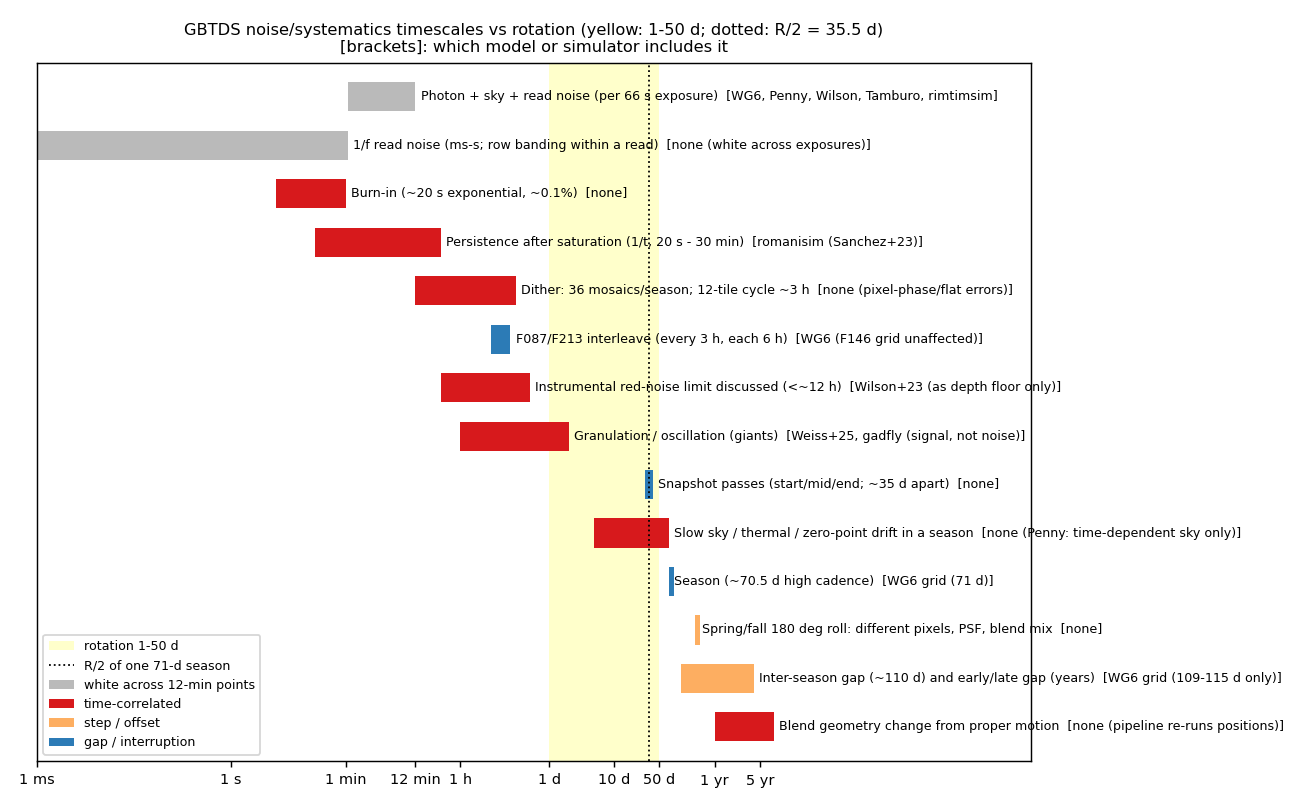

In [3]:
figlib.fig_timescales()
display(Image('figures/timescales.png'))

## 3. D5: F146/Kepler amplitude ratio
Weiss+2025 eq. 5 (oscillation amplitude scaling via Gadfly) vs our blackbody band-integrated spot-contrast ratios. The small-dT blackbody curve reproduces Weiss's formula, which checks the band approximation.

  teff  weiss2025_osc  bb_dT_small  bb_dT_15pct  bb_dT_30pct
3500.0          0.542        0.544        0.665        0.802
4000.0          0.551        0.547        0.656        0.783
4500.0          0.560        0.552        0.650        0.768
5000.0          0.569        0.557        0.646        0.756
5500.0          0.579        0.564        0.645        0.747
6000.0          0.589        0.570        0.645        0.740
6500.0          0.599        0.578        0.646        0.734


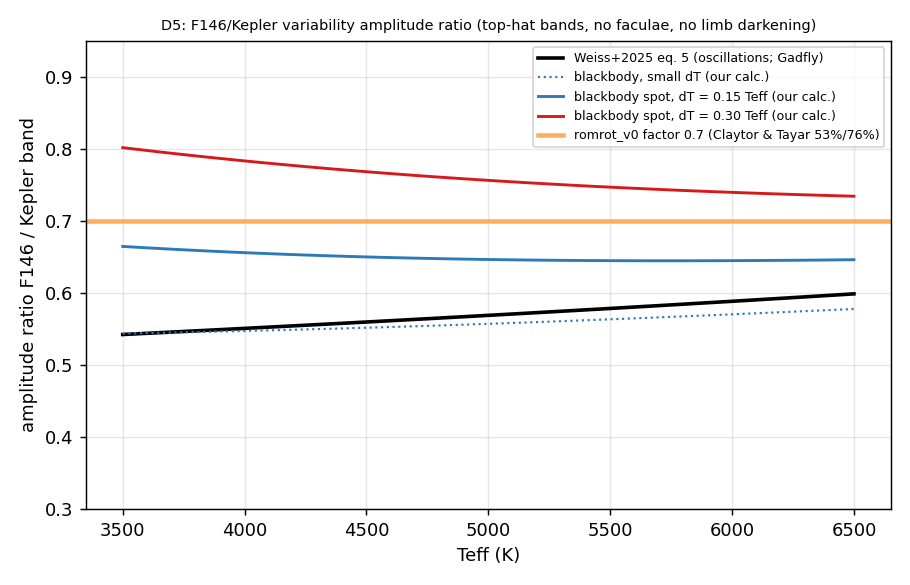

In [4]:
amp = figlib.fig_amp_ratio()
print(amp.iloc[::10].round(3).to_string(index=False))
display(Image('figures/f146_amp_ratio.png'))